## Regression

In [90]:
import pandas as pd 
import numpy as np

In [4]:
df= pd.read_csv("powerplant_data.csv")

In [6]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [8]:
# here,
# AT- temprature
# V- vacume
# AP- pressure
# RH- humidity 

# PE- produced energy (Target)

In [10]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [12]:
X=df.drop("PE", axis=1)
y=df["PE"]

In [14]:
from sklearn.model_selection import train_test_split 
X_train, X_test, y_train, y_test= train_test_split(X,y ,random_state=42, test_size=0.2)

In [15]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled= scaler.fit_transform(X_test)

In [18]:
import torch 
import torch.nn as nn 

X_train_tensor= torch.tensor(X_train_scaled, dtype=torch.float32) # we give here float as it is, also its scaled so now its numpy array so here we can directly acsses the values. 
X_test_tensor= torch.tensor(X_test_scaled, dtype= torch.float32)

y_train_tensor= torch.tensor(y_train.values, dtype= torch.float32).view(-1,1) # here its pandas sereas(not scaled) so to acsess its values we use
# ".values" also we use view to change the shape of the sereas into Pytorche's desired shape (-1) means automaticaly detect rows and (1) says now 
# we want it to have in column format, since y_train is in row format only (7564,). 
y_test_tensor= torch.tensor(y_test.values, dtype=torch.float32).view(-1,1)

In [20]:
# untill know we were having the 4 data catagories in our ram
from torch.utils.data import TensorDataset ,DataLoader 
train_dataset= TensorDataset(X_train_tensor, y_train_tensor) # its (i/p_feature, o/p_feature)
test_dataset= TensorDataset(X_test_tensor, y_test_tensor) # here we have fetched data from ram

In [22]:
train_loader= DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader= DataLoader(test_dataset, batch_size=32)
# know data is ready for training 

## Deep Learning

In [72]:
# Defining ANN model 
class ANN(nn.Module): # Inhereting parent class nn.module
    def __init__(self): 
        super(ANN, self).__init__()  # just one work call the parents class constructor(nn.module)

        self.model= nn.Sequential(  # here nn.sequntial i like a blueprint telling to process 1 at first ,then 2 ,etc...
            # 1st hidden layer , also self.model is variable encapsulating our model and sequntial is a pyotrch container holding our models layers.
            nn.Linear(X_train.shape[1],6), # shape[1], will tell how many features for i/p are there, and 6 there is the o/p feature.
            nn.ReLU(),
    
            # 2nd hidden layer
            nn.Linear(6,6), # this is a layer of y=6 neurons with x=6 inputs
            nn.ReLU(), # this the activation function giving non-linearity to the model for better line fitting according to the data.
    
            # output layer 
            nn.Linear(6,1),
        )

    def forward(self, x):
        return self.model(x)

In [74]:
# Building our model(object)
import torch.optim as optim # importing optimizers

model= ANN()

# solving regression so using MSE 
criterion= nn.MSELoss() # means mse is the loss function which will be used to make the model better
optimizer= optim.Adam(model.parameters(),lr=0.01) # in pytorch we dont have to initialise weight and bias so we directlt pass it here in the optimiser. 

In [76]:
# Trainig the ann ,we will have 100 epoch. 
val_losses= [] # validating the training
train_losses= [] # loss on trainig data 

best_val_loss= float("inf") # initially saved as infinity to later capture the lower loss value.

epochs= 100

for epoch in range(epochs): 
    model.train() #this is to train the model on each epoch.
    # know for each batch in an epoch.
    running_loss= 0.0 # totsl traning loss for one epoch

    for xb ,yb in train_loader:  # know data loader will give the: 
        # xb- Features(i/p) of each batch to train 
        # yb- labels(o/p) of each batch to be tested on.
        optimizer.zero_grad() # optemizer has a tendensy to accumulate the gradient so to set it 0 every time we use it.

        outputs= model(xb) # this will be forward pass ,and getting predicted output. 
        loss= criterion(outputs, yb) # here its given to calculate the loss in this forward pass.
        loss.backward() # backward propog. to compute gradients
        optimizer.step() # parameters updation

        running_loss += loss.item() # since loss is found by pytorch it will be in tenser so converting and storing it.

    epoch_train_loss= running_loss/len(train_loader) # this will tell ous avg. loss.
    train_losses.append(epoch_train_loss)

    # validation(not final test, but just done to see the model is trained in better way, so only needs forwrad propo. no optimizer or backw. propo)
    model.eval() # this will tell torch to stop adjusting the parameters know and just test.
    running_val_loss= 0.0

    with torch.no_grad(): # by default torch has autograd(automaticaly computes geadient)this is to stop it, this saves memory and speeds computation.
        for xb, yb in test_loader: 
            outputs= model(xb) 
            loss= criterion(outputs, yb)
            running_val_loss+= loss.item()

    epoch_val_loss= running_val_loss/len(test_loader) 
    val_losses.append(epoch_val_loss)

    print(f"epoch {epoch+1}/{epochs} ==> train loss = {epoch_train_loss} & val loss {epoch_val_loss}")

    if epoch_val_loss < best_val_loss: 
        best_val_loss= epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt")

epoch 1/100 ==> train loss = 93106.26287638347 & val loss 8530.604996744793
epoch 2/100 ==> train loss = 2197.315823173523 & val loss 354.4988983154297
epoch 3/100 ==> train loss = 171.22245212395987 & val loss 78.35878187815348
epoch 4/100 ==> train loss = 46.61940863529841 & val loss 35.364907328287764
epoch 5/100 ==> train loss = 28.76150055726369 & val loss 27.644545078277588
epoch 6/100 ==> train loss = 25.518856831391652 & val loss 22.595832316080728
epoch 7/100 ==> train loss = 23.074460140864055 & val loss 21.637946478525798
epoch 8/100 ==> train loss = 22.361368600527445 & val loss 21.274117708206177
epoch 9/100 ==> train loss = 22.09380310177803 & val loss 20.90917682647705
epoch 10/100 ==> train loss = 22.087437081336976 & val loss 20.362075106302896
epoch 11/100 ==> train loss = 21.807744669914246 & val loss 20.37183928489685
epoch 12/100 ==> train loss = 22.005270179112753 & val loss 20.194846614201865
epoch 13/100 ==> train loss = 22.061379702885947 & val loss 19.71253796

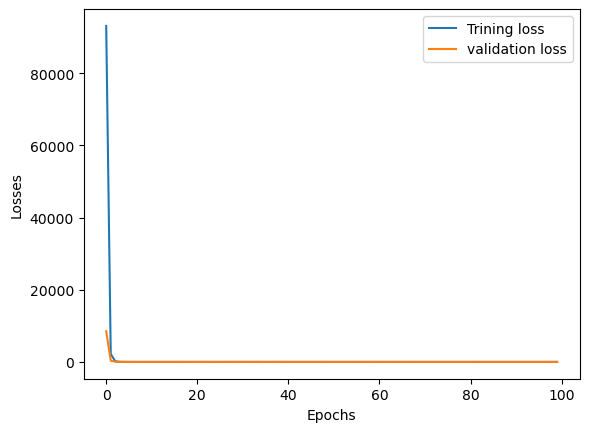

In [78]:
# so what happens here is that the loss is getting reduced but untill a threshold. 
import matplotlib.pyplot as plt

loss_df =pd.DataFrame({
    "Training loss": train_losses, 
    "val_loss": val_losses
})

plt.plot(loss_df["Training loss"], label="Trining loss")
plt.plot(loss_df["val_loss"], label="validation loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [80]:
# loading the best model 
model.load_state_dict(torch.load("best_model.pt")) # loading the best model parameter saved earlier ,to make the final one.

<All keys matched successfully>

In [84]:
# Evaluation
from sklearn.metrics import r2_score

model.eval()
with torch.no_grad(): # saving compute power. 
    train_pred= model(X_train_tensor)
    test_pred= model(X_test_tensor)

    train_mse_loss= criterion(train_pred, y_train_tensor) # (predicted, testing value)
    test_mse_loss= criterion(test_pred, y_test_tensor)

print("Training MSE:",train_mse_loss.item())
print("Testing MSE:",test_mse_loss.item())

print("R2 score:",r2_score(y_test, test_pred))

Training MSE: 19.068618774414062
Testing MSE: 17.65720558166504
R2 score: 0.9382926267473566


In [86]:
predicted_df= pd.DataFrame(test_pred.numpy(),columns=["Pridicted Values"])
actual_df= pd.DataFrame(y_test.values, columns=["Actual Values"])

pd.concat([predicted_df, actual_df], axis=1)

,Pridicted Values,Actual Values
0,433.651917,433.27
1,435.667572,438.16
2,460.536377,458.42
3,476.084900,480.82
4,433.675964,441.41
...,...,...
1909,451.381744,456.70
1910,432.152191,438.04
1911,468.456665,467.80
1912,433.076355,437.14


## Classification

In [97]:
df1= pd.read_csv("DateFruit_Dataset.csv")

df1.head() # 34 features and 1 class(category)

,AREA,PERIMETER,MAJOR_AXIS,MINOR_AXIS,ECCENTRICITY,EQDIASQ,SOLIDITY,CONVEX_AREA,EXTENT,ASPECT_RATIO,...,KurtosisRR,KurtosisRG,KurtosisRB,EntropyRR,EntropyRG,EntropyRB,ALLdaub4RR,ALLdaub4RG,ALLdaub4RB,Class
0,422163,2378.908,837.8484,645.6693,0.6373,733.1539,0.9947,424428,0.7831,1.2976,...,3.2370,2.9574,4.2287,-59191263232,-50714214400,-39922372608,58.7255,54.9554,47.8400,BERHI
1,338136,2085.144,723.8198,595.2073,0.5690,656.1464,0.9974,339014,0.7795,1.2161,...,2.6228,2.6350,3.1704,-34233065472,-37462601728,-31477794816,50.0259,52.8168,47.8315,BERHI
2,526843,2647.394,940.7379,715.3638,0.6494,819.0222,0.9962,528876,0.7657,1.3150,...,3.7516,3.8611,4.7192,-93948354560,-74738221056,-60311207936,65.4772,59.2860,51.9378,BERHI
3,416063,2351.210,827.9804,645.2988,0.6266,727.8378,0.9948,418255,0.7759,1.2831,...,5.0401,8.6136,8.2618,-32074307584,-32060925952,-29575010304,43.3900,44.1259,41.1882,BERHI
4,347562,2160.354,763.9877,582.8359,0.6465,665.2291,0.9908,350797,0.7569,1.3108,...,2.7016,2.9761,4.4146,-39980974080,-35980042240,-25593278464,52.7743,50.9080,42.6666,BERHI


In [99]:
X= df1.drop("Class", axis=1)
y= df1["Class"]

In [101]:
df1["Class"].unique()

array(['BERHI', 'DEGLET', 'DOKOL', 'IRAQI', 'ROTANA', 'SAFAVI', 'SOGAY'],
      dtype=object)

In [105]:
from sklearn.preprocessing import LabelEncoder

le= LabelEncoder()
y =le.fit_transform(y)

In [107]:
X_train, X_test, y_train, y_test= train_test_split(X,y, random_state=42, test_size=0.2)

In [111]:
X_train_scale= scaler.fit_transform(X_train)
X_test_scale =scaler.fit_transform(X_test)

## ANN

In [ ]:
# tensor conversion